<a href="https://colab.research.google.com/github/ThembaMapundu/MMA3001-Project/blob/main/notebooks/CO2_conc_overtime.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

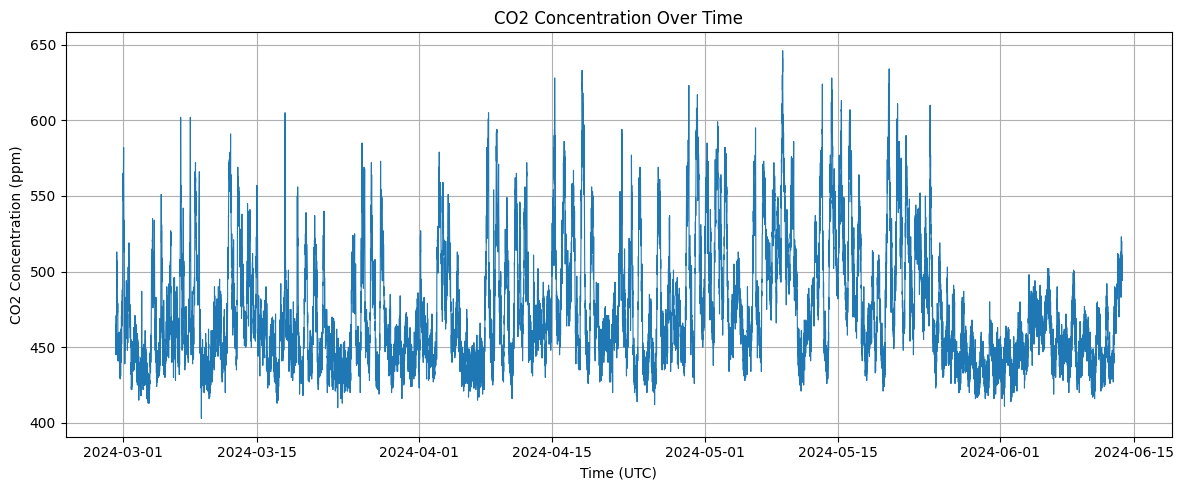

In [ ]:


# CO2 DATA ANALYSIS FOR CONCENTRATION WITHIN THE OBSERVATION PERIOD

# Import dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

#IMPORT DATA FROM GITHUB REPO
# Construct the raw GitHub URL
url = (f"https://raw.githubusercontent.com/ThembaMapundu/MMA3001-Project/main/SourceData/co2_clean.xlsx")

# Import Excel dataset from the url
data = pd.read_excel(url, engine="openpyxl")

# Select sensor, sensor with the most frequent readings
sensor_id = 6012002000869

# Filter data
sensor_data = data[data["sensor_id"] == sensor_id].copy()

# Convert timestamps
sensor_data["timestamp_utc"] = pd.to_datetime(sensor_data["timestamp_utc"],utc=True)

# Extract NumPy arrays
time = sensor_data["timestamp_utc"].dt.tz_localize(None).to_numpy()
co2 = sensor_data["co2_ppm"].to_numpy(dtype=float)

# Remove invalid observations (data with no time, data that is not a number and data that is less than 0)
valid = (~np.isnat(time)) & np.isfinite(co2) & (co2 > 0)

time = time[valid]
co2 = co2[valid]

# Sort by time
order = np.argsort(time)
time = time[order]
co2 = co2[order]

#print the results
#first plot, how CO2 changes across an observation period

plt.figure(figsize=(12, 5))
plt.plot(time, co2, linewidth=0.8)
plt.xlabel("Time (UTC)")
plt.ylabel("CO2 Concentration (ppm)")
plt.title("CO2 Concentration Over Time")
plt.grid()
plt.tight_layout()
plt.show()
